In [31]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.ticker import MultipleLocator, NullFormatter

import scipy
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit
from scipy.special import erf


import importlib

import delayscan
importlib.reload(delayscan)
try:
    importlib.reload(delayscan.TRclasses)
except:
    pass
from delayscan import TRclasses as tr

from delayscan.TRclasses import reduceBins

In [5]:
# Load default mpl style
plt.style.use("assets/TRPES.mplstyle")

#Other standard figure widths
fwid = 6.26894
ACSwid = 3.33
thesisWid = 14/2.54

#Dedault mpl colour tablet
colors = list(mcolors.TABLEAU_COLORS)

### Calibration data

In [6]:
# Instrument function parameters
# N0 * exp((-x)/l) + 1
IFparams = np.array([-6.90359945,  0.02964122])

# Low eKE cutoff at eKE = 0.126
IFcutoff = 0.126

In [7]:
# TOF to eKE calibration
# Flight tube length (m), time offset (ns), energy offset (eV)
calParams = np.array([  0.62209127, 48.29925437,  1.10221363])

### Data info

In [8]:
#Streaming potentials
SP_250618c = np.array([0.037811958986494684,  0.12997911802896056 ])
SP_250618d = np.array([-0.004002254614469857,  0.20421880748289375 ])



In [9]:
resultsPath = r"data/raw/"

# Data is organised like this (as we do at UCL)
# rf"{date}/{date}{fileIndex}/{date}{fileIndex}/"


In [10]:
# Here we provide the info to upload and process the data
# In each fileInfo_{date}{index} are the scans from each run
# (i.e., between pumping down and venting)
# I have only used one run but potentially could use more

# resultsFolder,date, fn, pump wl, pulseEnergy pump,probe wl, pulseEnergy probe, integration time, approx time 0, SP before, SP after 
fileInfo_250618b = [
    (resultsPath,"180625","dt", 350.0, 5, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    (resultsPath,"180625","dv", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    (resultsPath,"180625","dx", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    # (resultsPath,"180625","dz", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    (resultsPath,"180625","eb", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    (resultsPath,"180625","ec", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    (resultsPath,"180625","eg", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    (resultsPath,"180625","ei", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    (resultsPath,"180625","ek", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    (resultsPath,"180625","em", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
]


fileInfos = [fileInfo_250618b,]

In [11]:
allDelays = []
print("Loading files")
for fileInfo in fileInfos:
    scanSet = tr.DelayScanSet()
    for info in fileInfo:

        scan = tr.DelayScan(resultsFolder = info[0],
                            date = info[1],
                            fileIndex = info[2],
                            pumpWavelength = info[3],
                            pumpPulseEnergy = info[4],
                            probeWavelength = info[5],
                            probePulseEnergy = info[6],
                            integrationTime = info[7],
                            timeZero = info[8],
                            SPbefore = info[9],
                            SPafter = info[10],
                            calParams = calParams,
                            IFparams = IFparams,
                            IFcutoff = IFcutoff,
                            )
        scan.importData()
        scan.applyJacobian()
        scan.convert_to_eKE()
        scan.applyInstrumentFunction()
        scan.correctStreamingPotential()
        scan.normaliseByIntegrationTime()
        print(f"- {info[1]}{info[2]}")

        scanSet.append(scan)
    allDelays.append(scanSet)
print("Files loaded")

Loading files


- 180625dt
- 180625dv
- 180625dx
- 180625eb
- 180625ec
- 180625eg
- 180625ei
- 180625ek
- 180625em
Files loaded


### Plot one delay (to determine indices of pp, pump, probe, nothing)

In [12]:
scan = scanSet[1]
counts = [np.sum(scan.spectra[i::4,1]) for i in range(4)]


np.argsort(counts)


array([2, 0, 3, 1])

0: 71.7043 mm, tot counts: 1830
1: 71.7043 mm, tot counts: 14078
2: 71.7043 mm, tot counts: 0
3: 71.7043 mm, tot counts: 3890


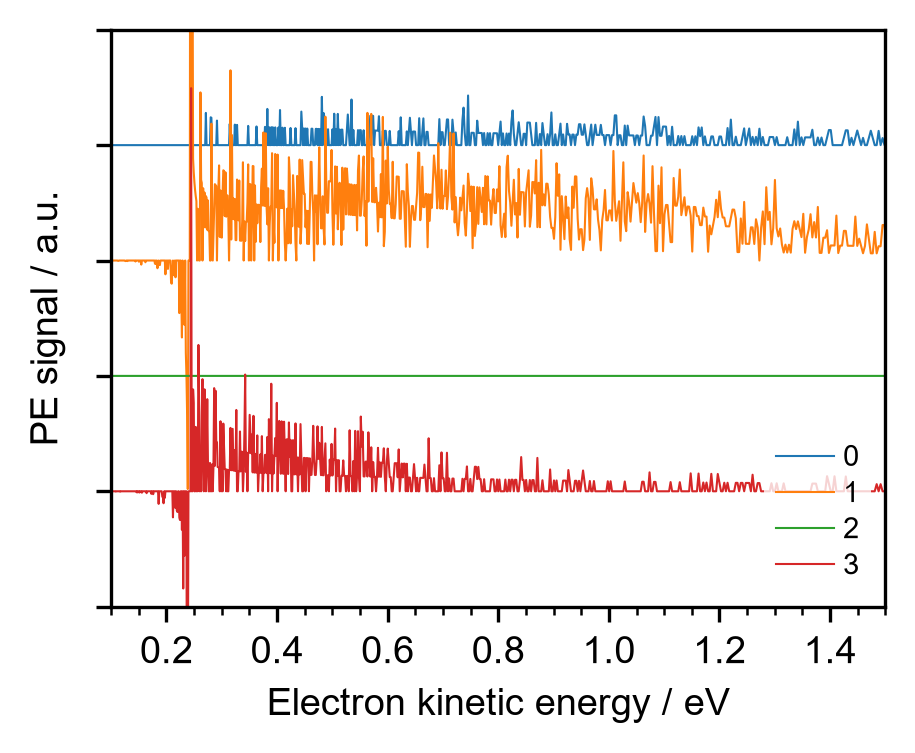

In [13]:
# Select one scan
# It doesn't matter which if they have all been recorded at the same time)
# Otherwise one should do this for each of them
scan = scanSet[1]
# Select one delay (preferably one where the pump-probe signal is strong enough)
# Here ind the index of the time delay
ind= 6 #0 to (len(delays))-1


fig,ax = plt.subplots()
for i,spectrum in enumerate(scan.spectra[ind*4:ind*4+4]): # *4 as there are 4 spectra per delay
    print(f"{i}: {scan.delays[ind]} mm, tot counts: {np.sum(spectrum[1]):.0f}")
    ax.plot(spectrum[0],spectrum[1]-i*50, lw=.5, label=f"{i}")

ax.set_xlim(0.1,1.5)
ax.set_ylim(-200,50)
ax.set_xlabel("Electron kinetic energy / eV")
ax.set_ylabel("PE signal / a.u.")
ax.set_yticklabels([])
ax.xaxis.set_major_locator(MultipleLocator(.2))
ax.xaxis.set_minor_locator(MultipleLocator(.05))

ax.legend(frameon=True,linewidth=0)
plt.show()

### Get subtracted spectra

In [14]:
#Here you subtract pump probe and nothing from pp by using the indices from above
# While the spectra are saved also saved as pps,pumps,probes and nothings
# the only important one is the first index as the others are all subtracted from it
print(scanSet.date)
for scan in scanSet:
    scan.subtract_background(1,3,0,2)

{'180625'}


In [15]:
# plot one scan to check subtraction was successsful
scan = scanSet[0]
subtracted_rebinned = []
rebins = 10

for spectrum in scan.subtracted:
    spectrum = spectrum[:,np.logical_and(spectrum[0]>=.3,spectrum[0]<=5)]
    rebinned_spectrum = reduceBins(spectrum,rebins)
    subtracted_rebinned.append(rebinned_spectrum)
subtracted_rebinned = np.array(subtracted_rebinned)


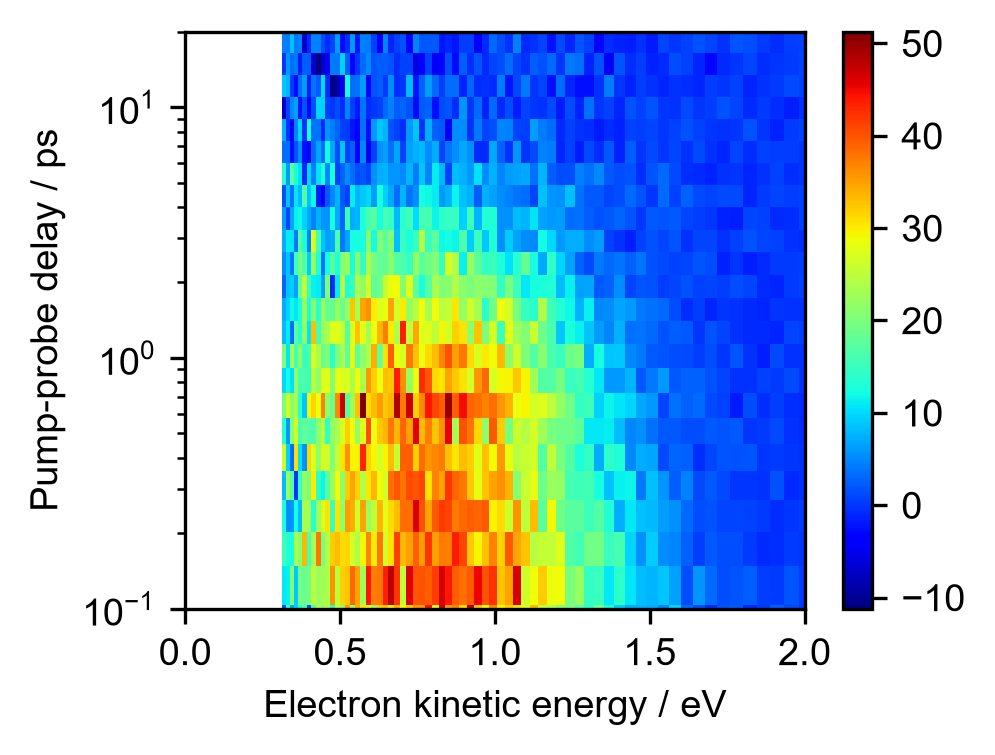

In [16]:
fig,ax = plt.subplots()
im0 = ax.pcolormesh(subtracted_rebinned[0,0],
                    scan.delayTimes,
                    subtracted_rebinned[:,1],
                    cmap='jet',
                    # shading='gouraud',
                   )

ax.set_yscale('log')
ax.set_xlim(0,2)
ax.set_ylim(.1,20)
ax.set_xlabel("Electron kinetic energy / eV")
ax.set_ylabel("Pump-probe delay / ps")
plt.colorbar(im0)

### Add scanSets from same day

1. Remove data points below eKE cutoff and above 5 eV
2. Sum intensities for the same eKE and time delay (this can only be done if you didn't change the time points at any point & are using the same SP measurements)
3. Rebin data if you like

There is some confusion in the naming when it comes to summed and subtracted

In [17]:

# 1. Remove data points below low eKE cutoff and above 5 eV
for scan in scanSet:
    print(f"Min eKE: {scan.IFcutoff+scan.streamingPotentialCorrection:.4f} eV")
    scan.trim_energies()



Min eKE: 0.3100 eV
Min eKE: 0.3100 eV
Min eKE: 0.3100 eV
Min eKE: 0.3100 eV
Min eKE: 0.3100 eV
Min eKE: 0.3100 eV
Min eKE: 0.3100 eV
Min eKE: 0.3100 eV
Min eKE: 0.3100 eV


In [18]:
# 2. Sum intensities for the same eKE and time delay (this can only be done if you didn't change the time points at any point & are using the same SP measurements)

scanSet.add_scans()


    

In [19]:
# 3. Rebin data if you like

rebins = 10
scanSet.rebin_subtracted_spectra(rebins)

### Plot heatmap of subtracted_rebinned

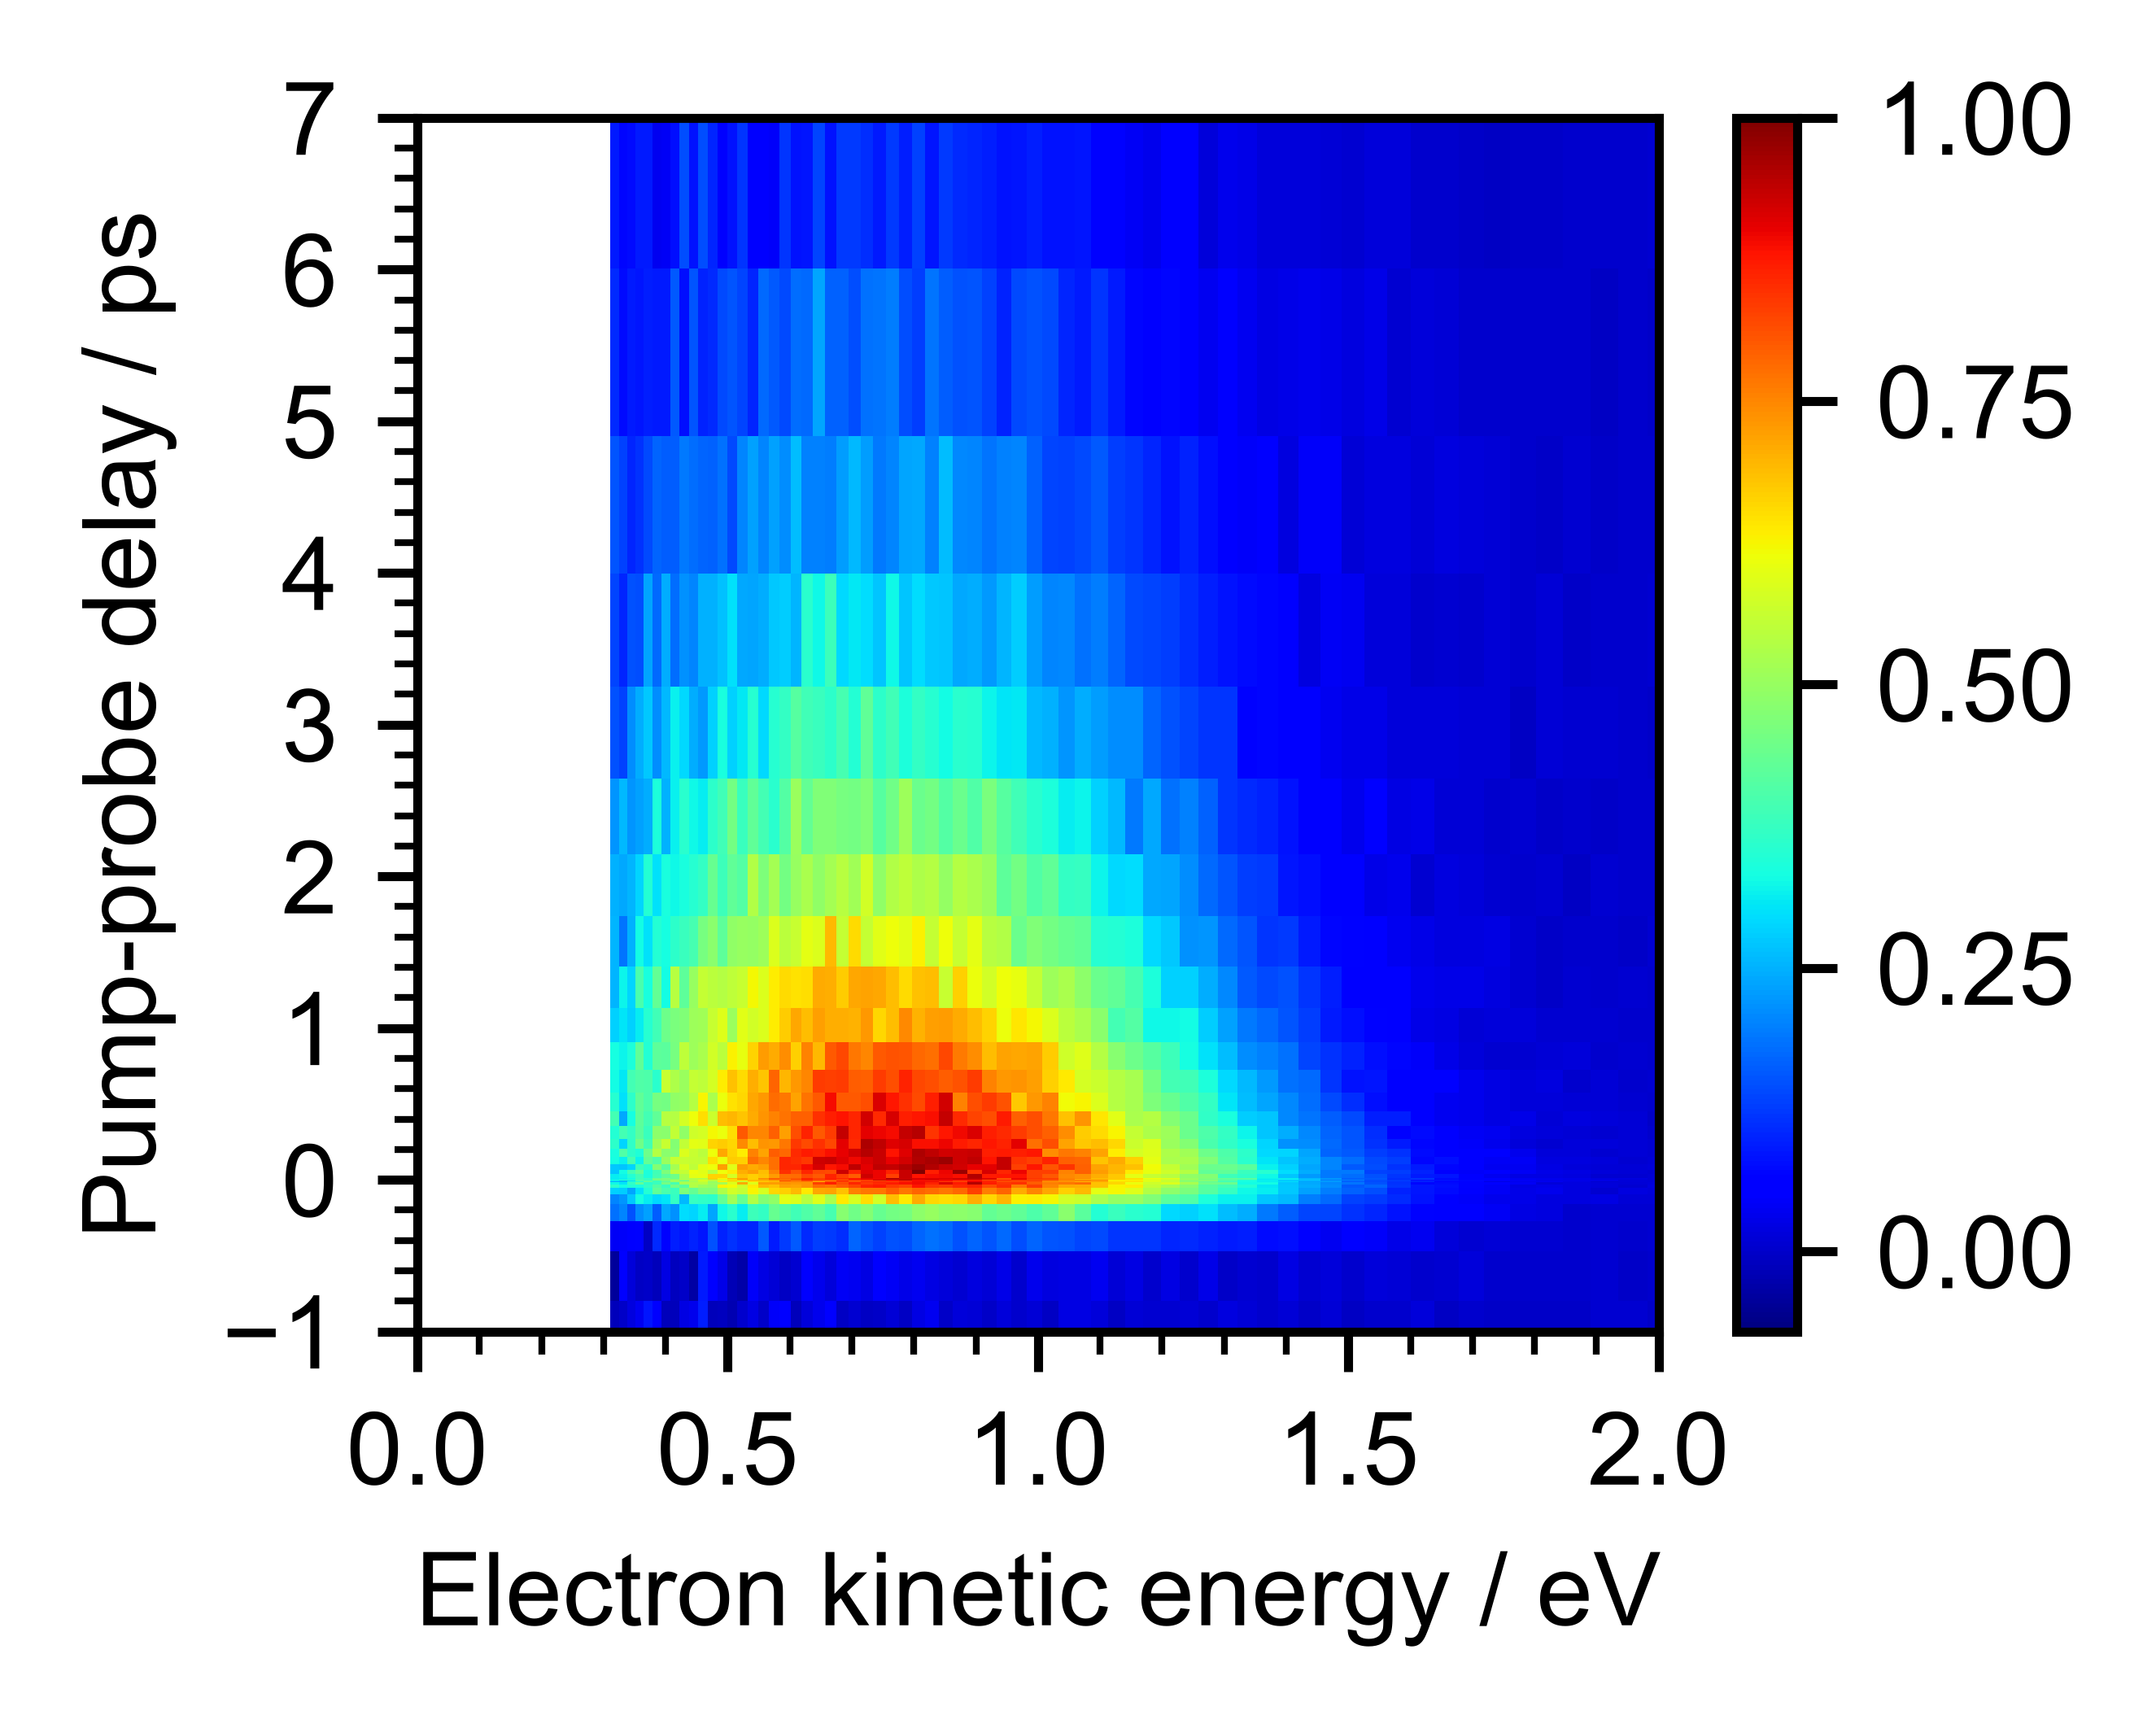

In [20]:
fig,ax = plt.subplots()
fig.set_dpi(1000)
fig.set_size_inches(20/3.2/2.54,15.5/3.2/2.5)

im0 = ax.pcolormesh(scanSet.energies_rebinned,
                    scanSet.delays,
                    scanSet.subtracted_rebinned,
                    cmap='jet',
                    # shading='gouraud',

                   )


ax.set_xlim(0,2)
ax.set_ylim(-1,7)
# ax.set_yscale('log')
# ax.set_ylim(0.01,10)
ax.set_xlabel("Electron kinetic energy / eV")
ax.set_ylabel("Pump-probe delay / ps")

ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(.1))
ax.yaxis.set_major_locator(MultipleLocator(1))
ax.yaxis.set_minor_locator(MultipleLocator(.2))
plt.colorbar(im0)

In [ ]:
# Save data
savepath = r"data/out/"
# Save unbinned data
save_arr = tr.create_save_arr(scanSet.energies,
                              scanSet.delays,
                              scanSet.subtracted)

np.savetxt(savepath+"ExperimentalData.csv",save_arr, delimiter = ',',fmt = "%.10e")


# Save binned data
save_arr = tr.create_save_arr(scanSet.energies_rebinned,
                              scanSet.delays,
                              scanSet.subtracted_rebinned)

np.savetxt(savepath+"RebinnedExperimentalData.csv",save_arr, delimiter = ',',fmt = "%.10e")

### Time-resolved data info

In [22]:
CROSS_CORRELATION = 0.320 #cross-correlation with 250 & 267
SIGMA = CROSS_CORRELATION / 2.355 
SIGMA

0.13588110403397027

### Find accurate t0

Determine ```t0``` by fitting the total counts with a sum of exponential (here are 1 and 2) and find the value of ```t0```.

 ```Sigma = cross_correlation/2.335``` can be set to a specific value or floated. 

In [42]:
# Define delays for simplicity
delays = scanSet.delays
#Integrate spectra to get total counts at each delay
trace = -np.trapezoid(scanSet.subtracted_rebinned,axis=1,x=scanSet.energies_rebinned)
trace /= max(trace)

#Make fit function with pre set SIGMA (you can also let it float if needed)
fit_func = lambda x,A1,tau1,t0: tr.monoexponential_witht0(x,A1,tau1,t0,SIGMA)

params,pcov=curve_fit(fit_func,scanSet.delays,trace,
                  p0=[0.8,1.8,0])
perr = np.sqrt(np.diag(pcov))

print("[A1, tau1, t0]")
print([float(f"{p:.4f}") for p in params])
print([float(f"{p:.4f}") for p in perr])

t0 = params[-1]
# Save t0 to scanSet?
scanSet.t0 = params[-1]
scanSet.delays_t0 = scanSet.delays - scanSet.t0


[A1, tau1, t0]
[1.1131, 2.8306, -0.196]
[0.0058, 0.046, 0.0032]


A1, tau1, t0
[1.1131, 2.8306, -0.196]
[0.0058, 0.046, 0.0032]


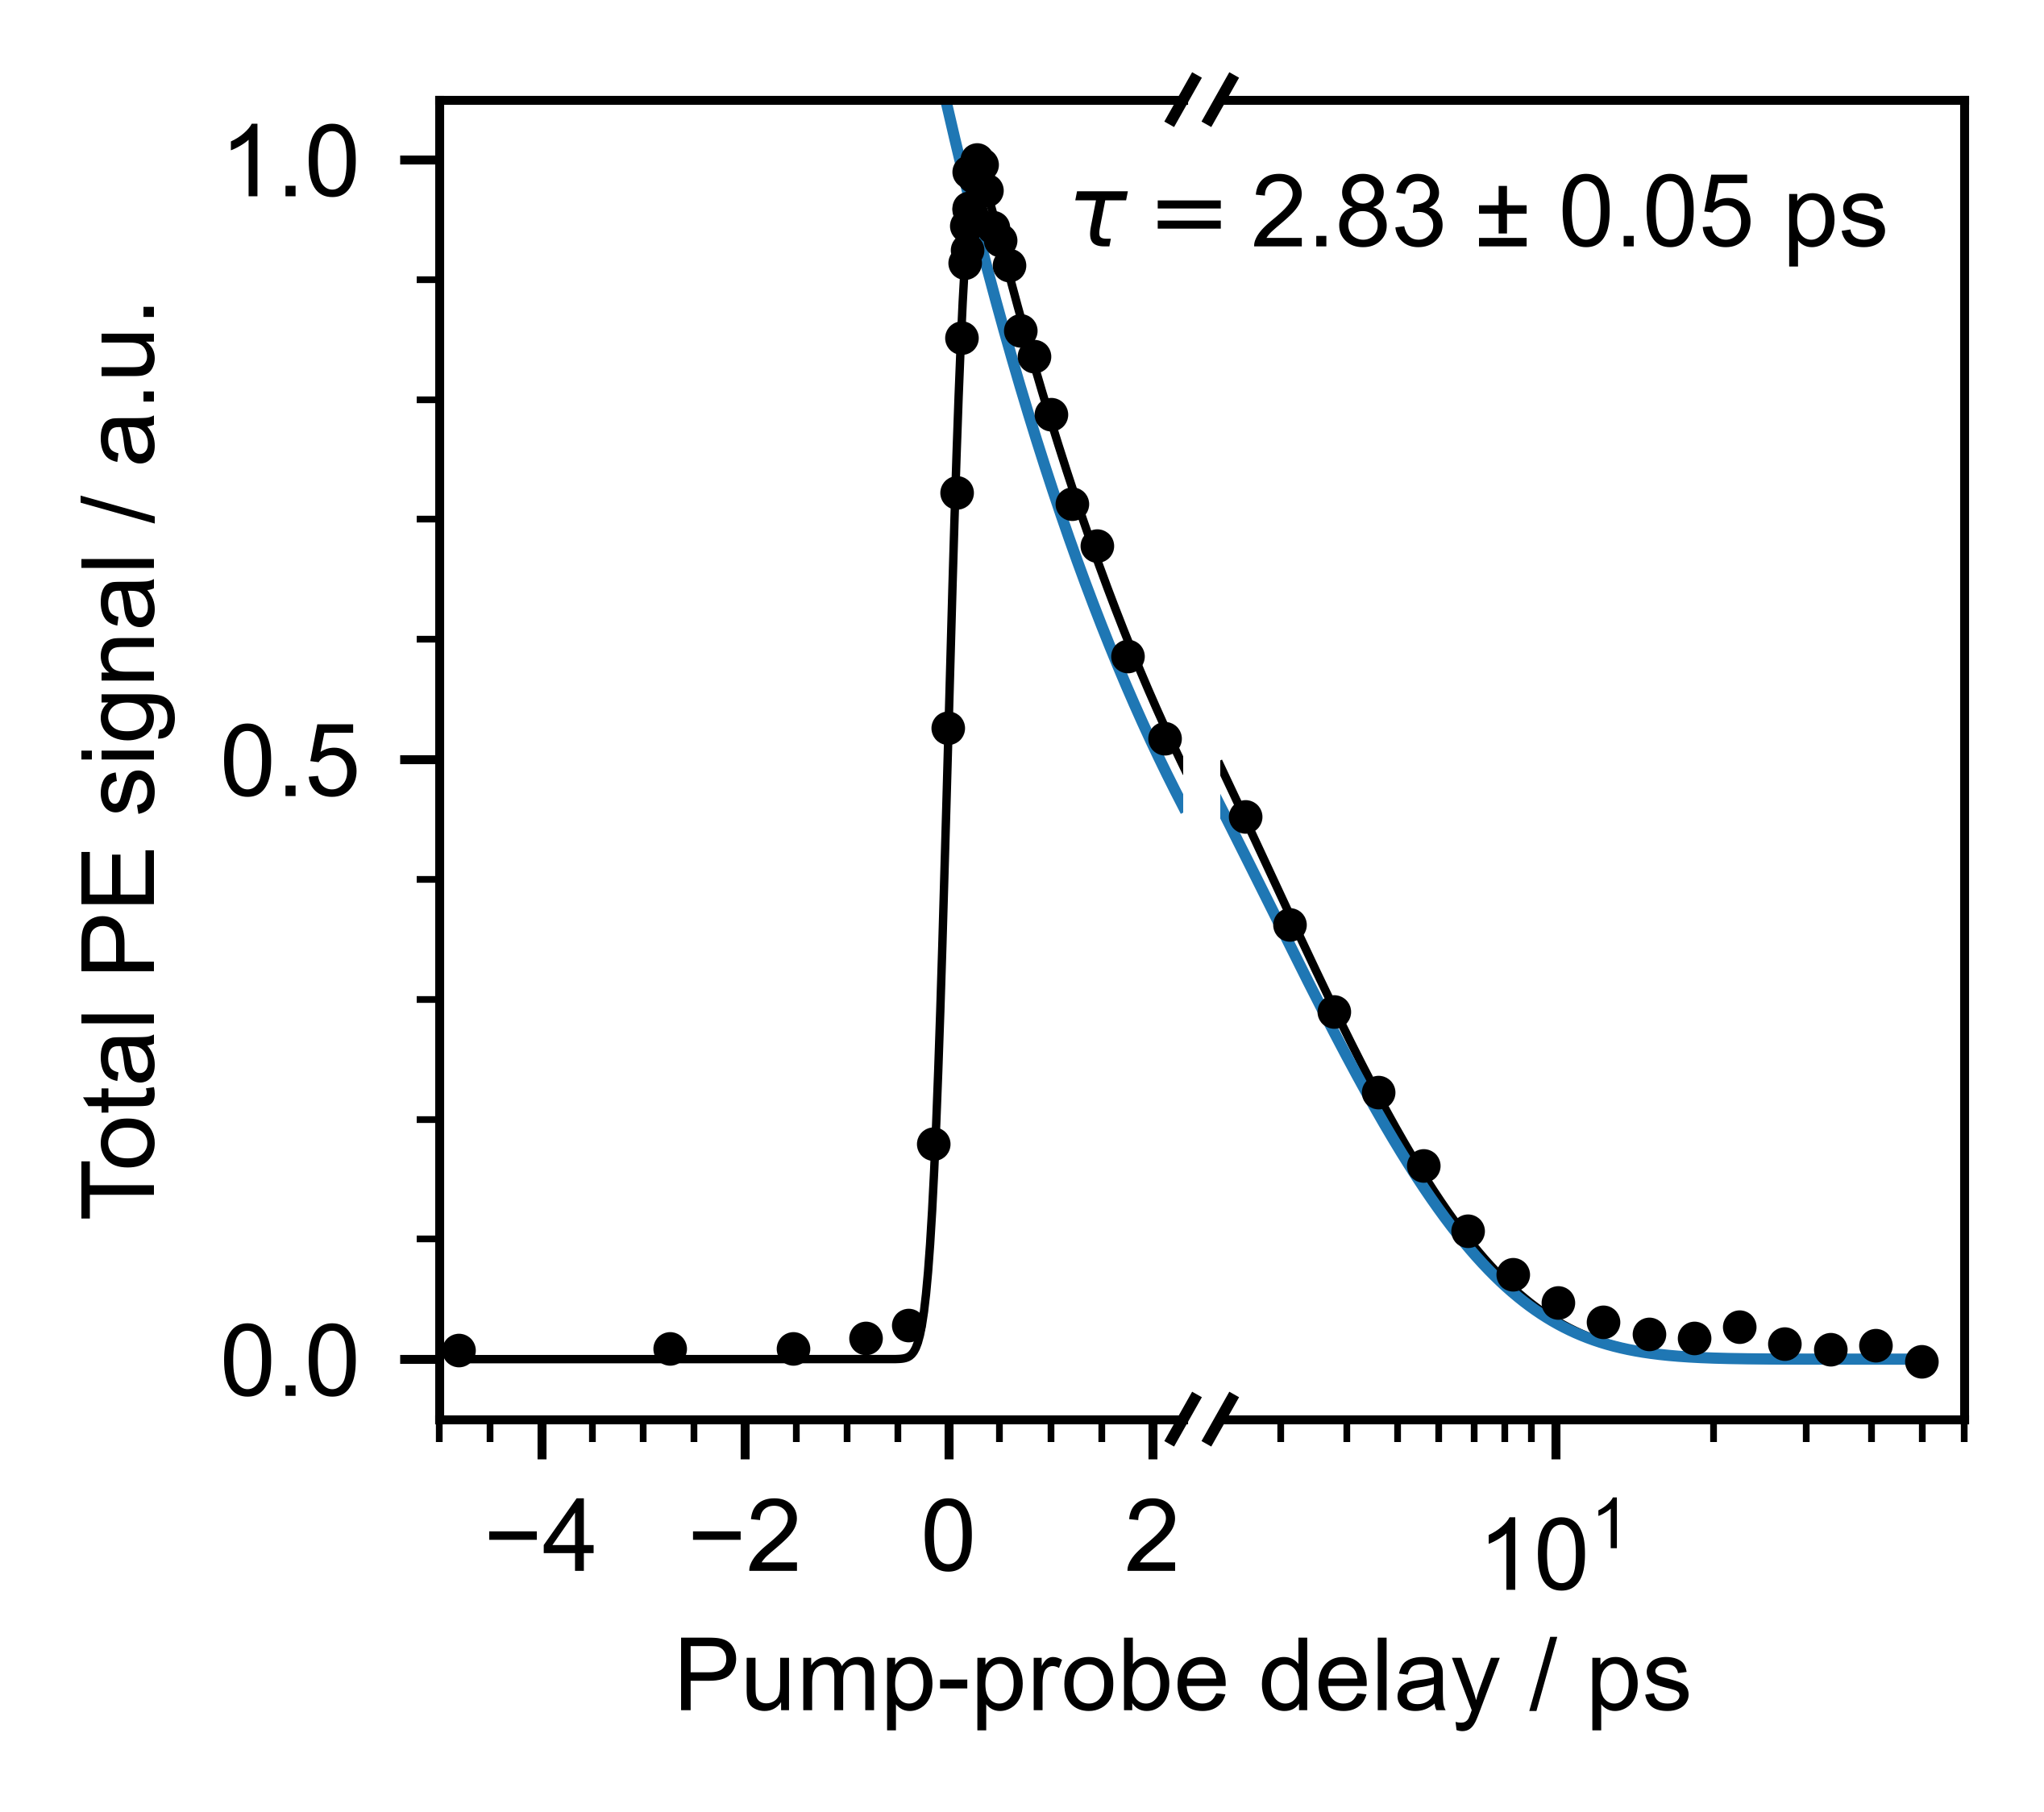

In [35]:
fig,axes = plt.subplots(1,2)
plt.subplots_adjust(wspace=0.05)
fig.set_dpi(1000)
fig.set_size_inches(15.5/2.5/2.54,13.5/2.5/2.54)
ax0,ax1 = axes
ts  =np.arange(-5,50,0.020)


for ax in axes:
    ax.plot(delays-t0,trace,'ko',ms=2,zorder=100)
    ax.plot(ts-t0,fit_func(ts,*params),'k',lw=.75)

print("A1, tau1, t0")
print([float(f"{p:.4f}") for p in params])
print([float(f"{p:.4f}") for p in perr])
ax0.set_xlim(-5,2.299)

ax1.set_xscale('log')
ax1.set_xlim(ax0.get_xlim()[1],60)

for ax in axes:
    ax.set_ylim(-.05,1.05)
ax1.set_yticklabels([])
ax1.set_yticks([])
ax0.set_ylabel("Total PE signal / a.u.")
ax0.set_xlabel("Pump-probe delay / ps",x=1)

ax1.text(.9,.95,f"$\\tau =${params[1]:.2f} ± {perr[1]:.2f} ps\n",ha='right',va='top',transform=ax.transAxes)
   
    
ax0.spines['right'].set_visible(False)
ax1.spines['left'].set_visible(False)
    
ax0.yaxis.set_major_locator(MultipleLocator(.5))
ax0.yaxis.set_minor_locator(MultipleLocator(.1))
ax0.xaxis.set_major_locator(MultipleLocator(2))
ax0.xaxis.set_minor_locator(MultipleLocator(.5))
ax1.xaxis.set_minor_formatter(NullFormatter())

# Add break markers
d = .015  # Size of diagonal lines
m=1 # Slope of diagonal lines
kwargs = dict(transform=ax0.transAxes, color='k', clip_on=False)
ax0.plot((1-d, 1+d), (-m*d, +m*d), **kwargs)      # top-left diagonal
ax0.plot((1- d, 1+ d), (1-m*d, 1+m*d), **kwargs)  # top-right diagonal

kwargs.update(transform=ax1.transAxes)  # switch to bottom axes
ax1.plot((-d, +d), (1 - m*d, 1 + m*d), **kwargs)  # bottom-left diagonal
ax1.plot((- d, + d), ( - m*d,  + m*d), **kwargs)  # bottom-right diagonal

    
fig.patch.set_alpha(0)

In [39]:
# Check biexponential
fit_func = (lambda x,A1,tau1,A2,tau2,t0: 
            tr.monoexponential_witht0(x,A1,tau1,t0,SIGMA) +
            tr.monoexponential_witht0(x,A2,tau2,t0,SIGMA))

params,pcov=curve_fit(fit_func,delays,trace,
                  p0=[0.101, 0.443, 0.495, 2.047,0.066])
perr = np.sqrt(np.diag(pcov))

print("A1, tau1, A2, tau2,t0")
print([float(f"{p:.4f}") for p in params])
print([float(f"{p:.4f}") for p in perr])

t0 = params[0]

A1, tau1, A2, tau2,t0
[1.0885, 2.6717, 0.0305, 31.5495, -0.1944]
[0.0182, 0.0841, 0.0196, 32.206, 0.003]


A1, tau1, A2, tau2,t0
[1.089, 2.672, 0.031, 31.549, -0.194]
[0.018, 0.084, 0.02, 32.206, 0.003]


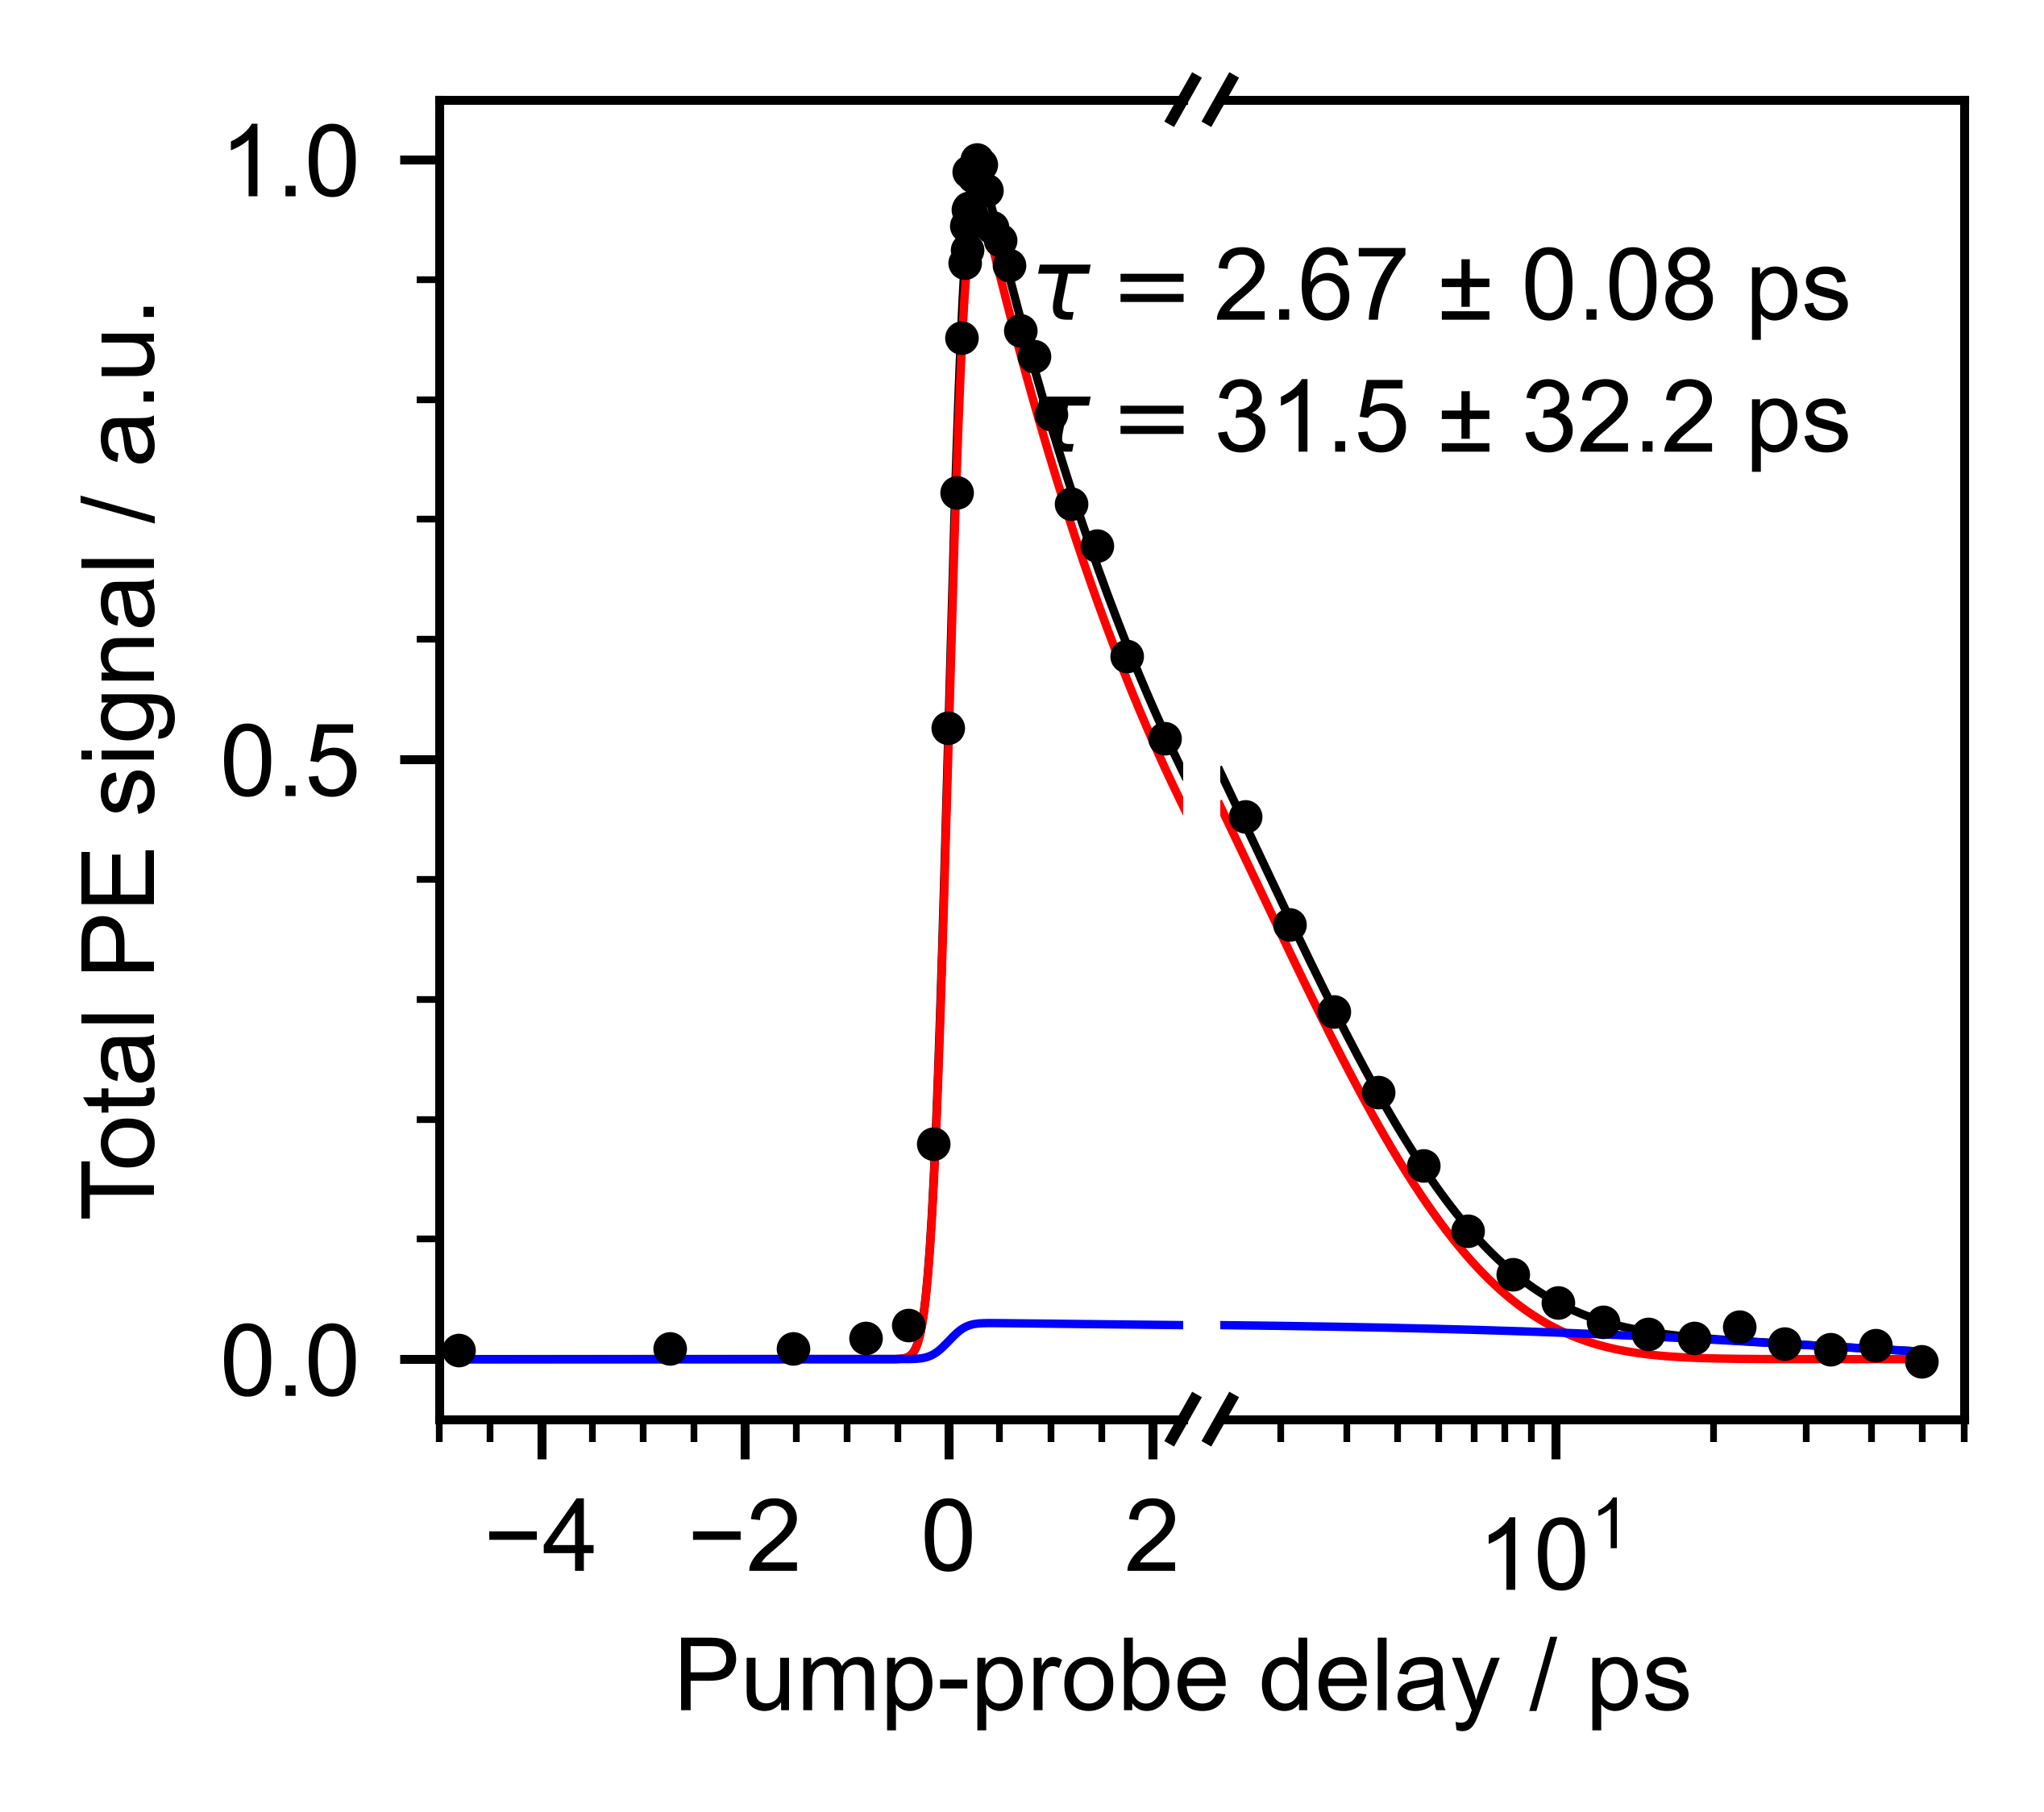

In [41]:
## biexponential
fig,axes = plt.subplots(1,2)
plt.subplots_adjust(wspace=0.05)
fig.set_dpi(1000)
fig.set_size_inches(15.5/2.5/2.54,13.5/2.54/2.5)
ax0,ax1 = axes
ts  =np.arange(-5,50,0.020)


t0 = params[-1]

for ax in axes:
    ax.plot(delays-t0,trace,'ko',ms=2,zorder=100)
    ax.plot(ts-t0,fit_func(ts,*params),'k',lw=.75)
    ax.plot(ts-t0,tr.monoexponential_witht0(ts,*params[:2],t0,SIGMA),'r',lw=.75)
    ax.plot(ts-t0,tr.monoexponential_witht0(ts,*params[2:4],t0,SIGMA),'b',lw=.75)
    
print("A1, tau1, A2, tau2,t0")
print([float(f"{p:.3f}") for p in params])
print([float(f"{p:.3f}") for p in perr])
ax0.set_xlim(-5,2.299)

ax1.set_xscale('log')
ax1.set_xlim(ax0.get_xlim()[1],60)

for ax in axes:
    ax.set_ylim(-.05,1.05)
ax1.set_yticklabels([])
ax1.set_yticks([])
ax0.set_ylabel("Total PE signal / a.u.")
ax0.set_xlabel("Pump-probe delay / ps",x=1)

ax1.text(.85,.75,f"$\\tau =${params[1]:.2f} ± {perr[1]:.2f} ps\n",ha='right',transform=ax.transAxes)
ax1.text(.85,.65,f"$\\tau =${params[3]:.1f} ± {perr[3]:.1f} ps\n",ha='right',transform=ax.transAxes)
   
    
ax0.spines['right'].set_visible(False)
ax1.spines['left'].set_visible(False)
    
ax0.yaxis.set_major_locator(MultipleLocator(.5))
ax0.yaxis.set_minor_locator(MultipleLocator(.1))
ax0.xaxis.set_major_locator(MultipleLocator(2))
ax0.xaxis.set_minor_locator(MultipleLocator(.5))
ax1.xaxis.set_minor_formatter(NullFormatter())


# Add break markers
d = .015  # Size of diagonal lines
m=1 # Slope of diagonal lines
kwargs = dict(transform=ax0.transAxes, color='k', clip_on=False)
ax0.plot((1-d, 1+d), (-m*d, +m*d), **kwargs)        # top-left diagonal
ax0.plot((1- d, 1+ d), (1-m*d, 1+m*d), **kwargs)  # top-right diagonal

kwargs.update(transform=ax1.transAxes)  # switch to bottom axes
ax1.plot((-d, +d), (1 - m*d, 1 + m*d), **kwargs)  # bottom-left diagonal
ax1.plot((- d, + d), ( - m*d,  + m*d), **kwargs)  # bottom-right diagonal

    
fig.patch.set_alpha(0)

### Save data with t0

In [43]:
# Save with t0 as 0 ps
savepath = r"data/out/"
save_arr = tr.create_save_arr(scanSet.energies_rebinned,
                              scanSet.delays_t0,
                              scanSet.subtracted_rebinned)

np.savetxt(savepath+"SubtractedSpectra.csv",save_arr,delimiter=',', fmt = "%.10e")

### Transients

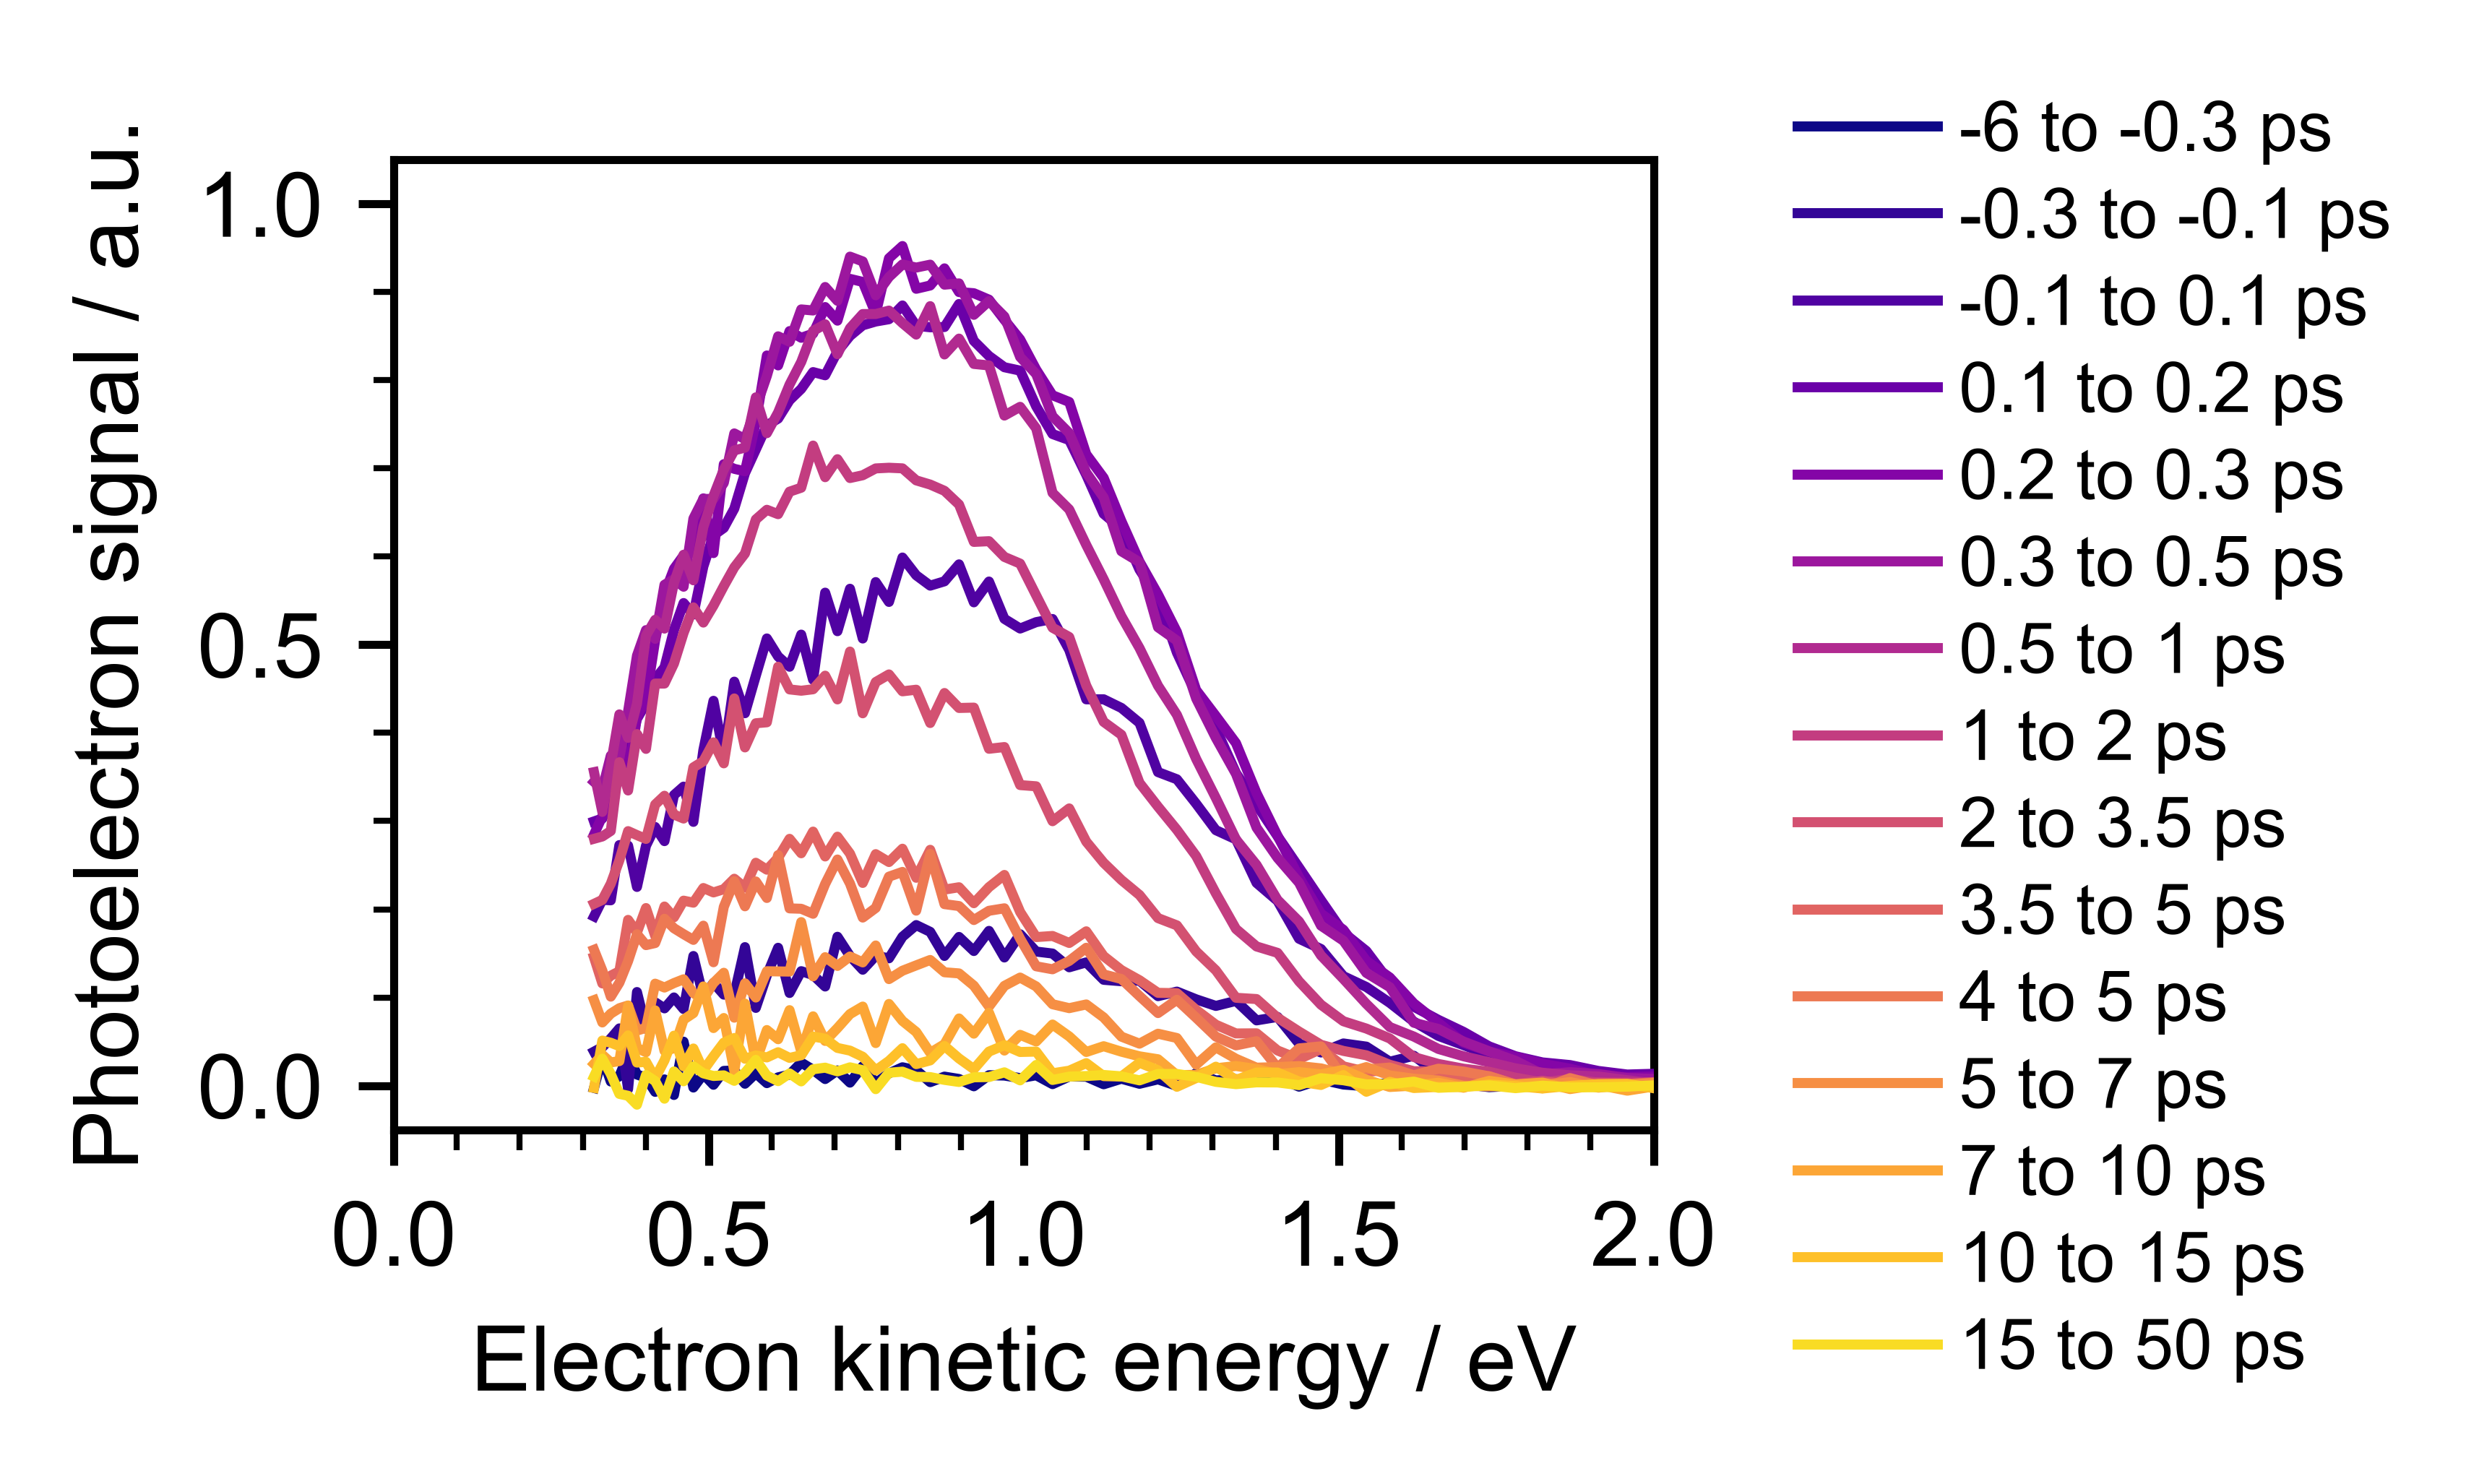

In [44]:
fig,ax = plt.subplots(1)
fig.set_dpi(1000)
fig.set_size_inches(20/3.5/2.54,15.5/2.54/3.5)

t0 = scanSet.t0
delays = scanSet.delays_t0

#Set limits for time ranges
timeRanges = [(-6,-.3),(-.3,-.1),(-.1,.1),(.1,.2),
              (.2,.3),(.3,.5),(.5,1),(1,2),(2,3.5),(3.5,5),(4,5),
              (5,7),(7,10),(10,15),(15,50),
             ]
#Create and normalise color map
cmap = plt.get_cmap('plasma')  # You can choose any colormap
norm = mcolors.Normalize(vmin=0, vmax=len(timeRanges))  # Normalize data from 0 to 100


for ind,timeRange in enumerate(timeRanges):
    #Mask data outside of time range
    mask = (np.logical_and(delays>timeRange[0],delays<=timeRange[1]))
    masked_data = scanSet.subtracted_rebinned[mask] 
    
    #Plot
    ax.plot(scanSet.energies_rebinned,np.mean(masked_data,axis=0),
            label = f"{timeRange[0]} to {timeRange[1]} ps",
            zorder=ind,
            c=cmap(norm(ind)),
           )

#Format
ax.set_xlim(0,2)
ax.set_ylim(-.05,1.05)

ax.set_ylabel("Photoelectron signal / a.u.")
ax.set_xlabel("Electron kinetic energy / eV")
    
ax.yaxis.set_major_locator(MultipleLocator(.5))
ax.yaxis.set_minor_locator(MultipleLocator(.1))
ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(.1))
ax.legend(frameon=False,bbox_to_anchor=[1.35, 0.4], 
           loc='center',ncol=1)

fig.patch.set_alpha(0)